## Parte 2: Aplicação de métodos — Regressão Linear

**Dataset:** `dataset_grupo_22.csv` — 2000 perfis de pacientes. **Variável a prever:** `target_regression`

### Objetivo
1. **Regressão Linear Simples:** ajustar um modelo com uma só feature, testar várias features e escolher a mais
   adequada.
2. **Regressão Linear Múltipla:** ajustar um modelo com várias features clínicas, experimentar combinações e
   determinar o melhor grupo.
3. **Comparação e discussão:** avaliar os dois modelos com R², MAE e RMSE e discutir os resultados.

### Ponto de partida: o que a EDA já nos disse
A análise exploratória (`01_EDA.ipynb`) deixou três indicações que orientam tudo o que se segue:

| Resultado da EDA | Consequência para a regressão |
|---|---|
| A correlação mais alta com o target é a do `bmi` (r ≈ 0.07). Todas as outras são ainda mais próximas de 0. | Na regressão simples, R² = r². Mesmo a melhor feature explicará **menos de 1%** da variância. **Não esperamos um bom modelo.** |
| As features são praticamente independentes entre si, exceto pares contínua/discretizada (`age`/`age_level`, `bmi`/`bmi_level`). | Juntar features pode acumular pequenos contributos, mas só faz sentido usar **uma versão** de cada variável. |
| `calcium_baseline` é constante; `systolic_index` e `age_normalized` são cópias de outras features; `ldl_alternative` tem os valores de `ldl` trocados entre pacientes (não pertence ao paciente da linha). | São removidas antes de modelar. |

O objetivo desta parte é, por isso, **testar de forma rigorosa** se alguma feature ou combinação consegue prever
o target melhor do que um modelo sem informação, e **explicar porquê** umas combinações funcionam melhor que
outras.

### Base teórica
- Regressão simples: $Y = \beta_0 + \beta_1 X + \varepsilon$. Múltipla: $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$.
- Coeficientes estimados por **mínimos quadrados**, minimizando $RSS = \sum (y_i - \hat y_i)^2$.
- $R^2 = 1 - RSS/TSS$: proporção da variância explicada. Testes *t* (cada coeficiente) e *F* (modelo global)
  avaliam a significância estatística.
- Problemas a vigiar: não-linearidade, variância não constante, *outliers*, **colinearidade**.

### Decisões de método
| Decisão | Porquê |
|---|---|
| *Holdout* 70% treino / 30% teste, seed 22 | Permitido pelo enunciado; proporção do exemplo Boston Housing; seed definida nas regras do projeto. |
| Escolhas feitas **só no treino**, com validação cruzada 5-fold | Escolher a melhor combinação olhando para o teste tornaria o erro do teste otimista. |
| Teste usado **uma única vez** (secção 4) | Estimativa honesta do erro em pacientes novos. |
| Comparação sempre com uma ***baseline*** (prever a média) | Um R² ou um RMSE só têm significado comparados com "não usar nenhuma feature". |
| `target_class` **não** é preditor | É o outro target do trabalho (regra do projeto). |

## 1. Preparação dos dados

### 1.1 Carregamento dos dados e preparação do ambiente

Carregamos as bibliotecas e o dataset original. O ficheiro CSV **nunca é alterado**: todas as transformações
são feitas numa cópia em memória.

Fixamos a semente aleatória em **22**. Assim, a divisão treino/teste e a
validação cruzada dão sempre os mesmos resultados, e qualquer membro do grupo pode reproduzir o notebook.

Usamos duas bibliotecas de regressão, como nas aulas:
- **scikit-learn** (`LinearRegression`), para treinar, prever e validar;
- **statsmodels** (`OLS`), para obter a tabela estatística (erros padrão, testes *t* e *F*, p-values)

In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next(p for p in candidates if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dimensao do dataset:', raw.shape)
raw[['age', 'bmi', 'HbA1c_level', 'smoking', 'employment_status', 'target_regression']].head()

Dimensao do dataset: (2000, 35)


,age,bmi,HbA1c_level,smoking,employment_status,target_regression
0,87,23.6000,7.0800,Never,Retired,90.0000
1,56,36.7000,8.2000,Never,Unemployed,220.0000
2,67,39.8000,6.8618,Current,Employed,172.0000
3,39,21.4000,6.9000,Current,Employed,92.0000
4,74,23.0000,7.0800,Never,Retired,152.0000


**Conclusões:** o dataset tem **2000 linhas e 35 colunas**, como na EDA. Há features numéricas (`age`, `bmi`,
`HbA1c_level`), categóricas em texto (`smoking`, `employment_status`) e o target, que varia entre valores como 90
e 220 nas primeiras linhas.

### 1.2 Remoção de features e codificação das categóricas

**O que fazemos e porquê:**

1. **Removemos as 4 features que a EDA (`01_EDA`) decidiu remover:**
   - `calcium_baseline`: é constante (9.42 em todas as linhas). Uma variável que não varia não consegue explicar
     a variação do target. Além disso, numa regressão ficaria colinear com o intercepto β₀.
   - `systolic_index`: é uma cópia exata de `systolic_bp`. Com as duas no modelo, a matriz $X^TX$ fica singular e
     $\hat\beta = (X^TX)^{-1}X^Ty$ deixa de ter solução única.
   - `age_normalized`: é uma reescala de `age`, com o mesmo problema;
   - `ldl_alternative`: tem os mesmos valores de `ldl`, mas trocados entre pacientes (coincide em só 18 de 2000
     linhas). O valor não pertence ao paciente da linha, por isso é ruído e não deve entrar no modelo.

2. **Convertemos as categóricas em números**, porque a regressão linear só trabalha com valores numéricos:
   - **ordinais** (têm uma ordem natural, ex.: Low < Medium < High) → códigos 0, 1, 2…, que preservam a ordem
     com uma única coluna;
   - **binárias** (Yes/No, Male/Female) → 0/1;
   - **nominais** sem ordem (`employment_status`) → *one-hot* com `drop_first=True`, tal como `pd.get_dummies` no
     exercício PL2 (Insurance). Se não retirássemos uma coluna, as *dummies* somariam sempre 1 e ficariam
     colineares com o intercepto ("armadilha das *dummies*").

3. **Retiramos os dois targets da matriz de preditores.** `target_class` é o outro resultado a prever no trabalho;
   usá-lo para prever `target_regression` seria usar um resultado para prever outro.

As features "pouco informativas" da EDA **não** são removidas aqui. A ideia desta parte é precisamente testá-las
e deixar que os resultados confirmem (ou não) o que a EDA sugeriu.

In [2]:
TARGET = 'target_regression'
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']

ORDINAL = {
    'age_level':         ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level':         ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking':           ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level':      ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level':   ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_class'])
y = data[TARGET]
assert X.isna().sum().sum() == 0, 'codificacao gerou valores em falta'
FEATURES = list(X.columns)
CONTINUOUS = [c for c in FEATURES if c in raw.columns and pd.api.types.is_numeric_dtype(raw[c])]
print(f'{len(FEATURES)} features candidatas ({len(CONTINUOUS)} numericas continuas):')
print(FEATURES)

30 features candidatas (17 numericas continuas):
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'plasma_value', 'employment_status_Retired', 'employment_status_Unemployed']


**Conclusões:** ficam **30 features candidatas** (35 colunas − 4 removidas − 2 targets), das quais 17 são
numéricas contínuas e 13 vêm de categóricas codificadas. `employment_status` deu origem a 2 colunas
(`Retired` e `Unemployed`; `Employed` é a categoria de referência, representada por 0 nas duas). A codificação não
gerou valores em falta.

### 1.3 Divisão em treino e teste (*holdout*)

O enunciado permite avaliar com o método *holdout*: separar os dados em treino e teste.
- O modelo **aprende** os coeficientes β apenas com o conjunto de **treino**.
- O conjunto de **teste** simula "pacientes novos" e mede a capacidade de **generalização**.

Usamos **70% / 30%**, ficando 1400 registos para treinar,
o que é suficiente para estimar poucos coeficientes, e 600 para testar, o que dá uma estimativa razoável do erro.

**Regra importante:** todas as escolhas (que feature, que combinação) são feitas **só com o treino**. O teste é
usado uma única vez, no fim (secção 4). Se escolhêssemos a combinação que dá menos erro no teste, o próprio teste
passaria a fazer parte da escolha, e o erro reportado seria otimista.

Verificamos também se o target tem distribuição semelhante nos dois conjuntos. Se não tivesse, o teste não seria
representativo.

treino: (1400, 30) | teste: (600, 30)
           count     mean     std     min      25%      50%      75%      max
treino 1400.0000 136.9237 41.3707 70.0000 103.0000 135.0000 167.0000 300.0000
teste   600.0000 133.8167 40.9325 70.0000  97.0000 131.0000 164.0000 300.0000

Teste de Kolmogorov-Smirnov (mesma distribuicao?): p = 0.288


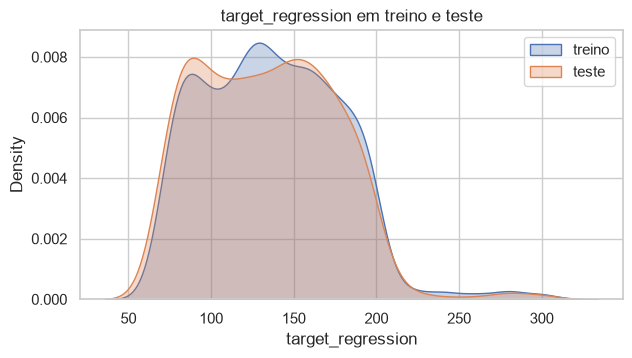

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
print('treino:', X_train.shape, '| teste:', X_test.shape)
print(pd.DataFrame({'treino': y_train.describe(), 'teste': y_test.describe()}).T)
print(f'\nTeste de Kolmogorov-Smirnov (mesma distribuicao?): p = {stats.ks_2samp(y_train, y_test).pvalue:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(y_train, ax=ax, label='treino', fill=True, alpha=.3)
sns.kdeplot(y_test, ax=ax, label='teste', fill=True, alpha=.3)
ax.set_title('target_regression em treino e teste'); ax.legend(); plt.show()

**Conclusões:** o treino tem **1400** registos e o teste **600**. As distribuições do target são semelhantes nos
dois conjuntos:
- médias de 136.9 e 133.8, desvios padrão de 41.4 e 40.9, e o mesmo intervalo (70–300);
- o teste de Kolmogorov-Smirnov não encontra diferença (p = 0.288).

**Justificação:** a divisão aleatória produziu um teste representativo. As diferenças que encontrarmos entre
treino e teste serão do modelo, não de uma divisão desequilibrada.

### 1.4 Métricas de avaliação, validação cruzada e modelo de referência (*baseline*)


| Métrica | Fórmula | O que diz |
|---|---|---|
| **R²** | $1 - RSS/TSS$ | Proporção da variância do target explicada pelo modelo. 1 = perfeito; **0 = tão bom como prever sempre a média**; negativo = pior que a média. |
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | Erro médio absoluto, nas unidades do target. Fácil de interpretar e pouco sensível a erros grandes isolados. |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | Raiz do erro quadrático médio, também nas unidades do target. Penaliza mais os erros grandes, porque eleva-os ao quadrado. |

**Porquê validação cruzada (5-fold) dentro do treino?** Para escolher entre features/combinações precisamos de
medir o erro em dados que o modelo não viu, mas sem tocar no teste. A validação cruzada divide o treino em 5
partes: treina com 4, avalia na 5.ª, e repete 5 vezes. A média das 5 avaliações é mais estável do que uma única
divisão.

**Porquê uma *baseline*?** Um modelo sem nenhuma feature prevê sempre a média do treino. Um R² ou um RMSE só têm
significado comparados com isto: **se um modelo não erra menos que a média, as features não acrescentam
informação.** É o equivalente, na regressão, a um classificador que prevê sempre a classe maioritária.

A padronização (`StandardScaler`) não altera as previsões de uma regressão linear, apenas a escala dos
coeficientes. Incluímo-la para os coeficientes serem comparáveis entre si e para preparar a Parte 4 (Ridge/Lasso),
onde é obrigatória.

In [4]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

def make_model(degree=1):
    """Regressao linear (opcionalmente com termos polinomiais) com padronizacao."""
    steps = [PolynomialFeatures(degree, include_bias=False)] if degree > 1 else []
    return make_pipeline(*steps, StandardScaler(), LinearRegression())

def cv_scores(model, cols, Xd=None, yd=None):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    r = cross_validate(model, Xd[cols], yd, cv=CV, scoring=SCORING, return_train_score=True)
    return {'train_r2': r['train_r2'].mean(), 'cv_r2': r['test_r2'].mean(), 'cv_r2_std': r['test_r2'].std(),
            'cv_mae': -r['test_mae'].mean(), 'cv_rmse': -r['test_rmse'].mean()}

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}

baseline_cv = cv_scores(DummyRegressor(strategy='mean'), FEATURES)
print(f'Desvio padrao do target no treino: {y_train.std():.3f}')
pd.Series(baseline_cv, name='baseline (media)').to_frame().T

Desvio padrao do target no treino: 41.371


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
baseline (media),0.0000,-0.0059,0.0037,33.9541,41.3848


**Conclusões:** a *baseline* erra, em média, **34.0 unidades (MAE)**, com RMSE de **41.4**. Este RMSE é
praticamente igual ao desvio padrão do target (41.37), o que é esperado: prever sempre a média produz um erro
igual à dispersão natural dos dados.

**Este é o valor a bater.** Uma feature só é útil se fizer o RMSE descer claramente abaixo de 41.4.

**Nota sobre o R² da baseline:** em validação cruzada não é exatamente 0, mas −0.006. Em cada fold a média é
calculada com os dados de treino desse fold e avaliada noutros dados, onde a média real é ligeiramente diferente.
Por isso, ao longo do notebook, **comparamos os modelos com a baseline (−0.006) e não com o zero.**

## 2. Regressão Linear Simples

$$\hat y = \hat\beta_0 + \hat\beta_1 x$$

Uma só feature tenta explicar o target. Os coeficientes são escolhidos por **mínimos quadrados**, isto é, de
forma a minimizar $RSS = \sum (y_i - \hat y_i)^2$.

**Estratégia:**
1. Calcular, a partir da EDA, **qual é o melhor R² possível** (2.1).
2. Testar **todas** as features, uma a uma (2.2).
3. Comparar com uma **feature aleatória**, para saber se as melhores são diferentes de ruído (2.3).
4. Analisar em detalhe o modelo escolhido, com visualizações e resíduos (2.4–2.6).
5. Verificar se uma relação **não-linear** (polinómio) seria melhor (2.7).

### 2.1 O que esperar? O limite que a EDA já nos dá

Na regressão linear simples há uma relação direta entre a correlação de Pearson e o R²:

$$R^2_{\text{treino}} = r^2$$

Ou seja, **a correlação calculada na EDA diz-nos, antes de treinar qualquer modelo, qual é o R² máximo**
que cada feature pode atingir no treino. Na EDA, a correlação mais alta com o target foi a do `bmi` (r ≈ 0.07).
Calculamos r e r² para todas as features no conjunto de treino.

In [5]:
r_train = X_train.corrwith(y_train)
expected = pd.DataFrame({'r (treino)': r_train, 'r2 = R2 maximo esperado': r_train ** 2,
                         '% variancia explicada': r_train ** 2 * 100})
expected.sort_values('r2 = R2 maximo esperado', ascending=False).head(10)

,r (treino),r2 = R2 maximo esperado,% variancia explicada
bmi,0.0741,0.0055,0.5489
age,0.0699,0.0049,0.4879
age_level,0.0612,0.0037,0.3740
smoking,-0.0603,0.0036,0.3639
salt_intake,-0.0568,0.0032,0.3228
triglycerides,0.0530,0.0028,0.2814
bmi_level,0.0504,0.0025,0.2541
physical_activity,0.0496,0.0025,0.2464
HbA1c_level,0.0437,0.0019,0.1913
high_ldl_cholesterol,0.0396,0.0016,0.1572


**Conclusões:** antes de treinar qualquer modelo, já sabemos o **melhor R² de treino possível** para uma
regressão simples:
- **`bmi`: r = 0.074 → R² máximo = 0.0055**, ou seja, **0.55%** da variância do target;
- `age` vem a seguir com 0.49%, depois `age_level` (0.37%) e `smoking` (0.36%).

**Justificação:** com uma só feature, a reta de mínimos quadrados explica exatamente r² da variância. Como nenhuma
feature tem |r| acima de 0.075, **nenhuma regressão simples pode explicar mais de ~0.5% da variância**, nem no
treino. Este resultado confirma numericamente o que a EDA indicava: mesmo a melhor feature não dará um modelo
bom.

### 2.2 Testar todas as features, uma de cada vez

Para cada uma das 30 features ajustamos uma regressão simples e registamos:
- **R² de treino** (deve coincidir com r² da tabela anterior);
- **β₁ e o seu p-value** (teste *t* para $H_0: \beta_1 = 0$). Um p-value < 0.05 indica que a relação
  é estatisticamente significativa;
- **R², MAE e RMSE em validação cruzada**: este é o **critério de escolha**, porque mede o desempenho em dados que
  não foram usados para estimar os coeficientes.

A tabela fica ordenada pelo RMSE de CV (menor = melhor). Mostramos a *baseline* para comparação.

In [6]:
rows = []
for f in FEATURES:
    ols = sm.OLS(y_train, sm.add_constant(X_train[[f]])).fit()
    cv = cv_scores(make_model(), [f])
    rows.append({'feature': f, 'R2_treino': ols.rsquared, 'beta1': ols.params[f], 'p_value': ols.pvalues[f],
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse'],
                 'melhor que baseline?': cv['cv_rmse'] < baseline_cv['cv_rmse']})
simple = pd.DataFrame(rows).set_index('feature').sort_values('cv_rmse')
print('Baseline: CV R2 = {cv_r2:.4f} | CV MAE = {cv_mae:.3f} | CV RMSE = {cv_rmse:.3f}'.format(**baseline_cv))
print(f"Features com p < 0.05: {(simple['p_value'] < 0.05).sum()} de {len(simple)}")
print(f"Features com CV RMSE menor que a baseline: {simple['melhor que baseline?'].sum()} de {len(simple)}")
simple

Baseline: CV R2 = -0.0059 | CV MAE = 33.954 | CV RMSE = 41.385
Features com p < 0.05: 6 de 30
Features com CV RMSE menor que a baseline: 11 de 30


,R2_treino,beta1,p_value,cv_r2,cv_mae,cv_rmse,melhor que baseline?
feature,,,,,,,
bmi,0.0055,0.4254,0.0055,-0.0024,33.9732,41.3094,True
age,0.0049,0.1412,0.0089,-0.0028,33.8315,41.3234,True
age_level,0.0037,2.6719,0.0221,-0.0036,33.8664,41.3393,True
bmi_level,0.0025,1.9577,0.0594,-0.0038,33.9739,41.3410,True
HbA1c_level,0.0019,3.1327,0.1019,-0.0043,34.0091,41.3526,True
smoking,0.0036,-3.0273,0.0240,-0.0044,33.9326,41.3553,True
salt_intake,0.0032,-0.6723,0.0335,-0.0053,33.8729,41.3683,True
blood_pressure,0.0012,0.2771,0.1946,-0.0051,33.9363,41.3685,True
physical_activity,0.0025,2.5201,0.0634,-0.0054,33.9736,41.3725,True


**Conclusões:**
- O R² de treino de cada feature **coincide com r²** da tabela anterior (`bmi`: 0.0055), o que confirma a relação
  R² = r².
- **`bmi` é a melhor feature** em todos os critérios: maior R² de treino, menor RMSE de CV (41.309) e o p-value
  mais baixo (0.0055). Seguem-se `age` (RMSE 41.323) e `age_level` (41.339).
- **6 das 30 features têm β₁ significativo** (p < 0.05): `bmi`, `age`, `age_level`, `smoking`, `salt_intake` e
  `triglycerides`.
- Apenas **11 das 30** têm RMSE de CV abaixo da baseline, e **nenhuma tem R² de CV positivo** (o melhor é −0.0024,
  do `bmi`).

**Justificação — porque é que estas features ficam à frente?** São as que têm maior |r| com o target (secção
2.1). `bmi` e `age` aparecem sempre no topo: na tabela de correlações da EDA, nos p-values e agora no erro de
validação.

**Porque é que o ganho é tão pequeno?** O `bmi` baixa o RMSE de 41.385 (baseline) para 41.309: **menos de 0.1
unidades**, num target com desvio padrão de 41. Isto acontece porque o `bmi` explica apenas 0.55% da variância:
os restantes 99.45% continuam por explicar.

**Significância ≠ capacidade de previsão.** O β₁ do `bmi` é significativo (p = 0.006) porque, com 1400 registos,
até efeitos minúsculos se distinguem de zero. O p-value diz que o efeito provavelmente **existe**; não diz que é
**grande** ou útil para prever.

### 2.3 As melhores features são diferentes de ruído?

Quando a relação entre X e Y é **aleatória**, o R² fica perto de 0 e o
coeficiente não é significativo. Usamos essa ideia como **controlo**: criamos 500 features de **ruído puro**
(números aleatórios sem qualquer relação com o target), ajustamos uma regressão simples com cada uma e vemos que
R² de treino obtemos **só por acaso**.

Se o R² do `bmi` ficar claramente acima do que o ruído consegue, a relação é real (ainda que fraca). Se ficar no
meio da distribuição do ruído, o `bmi` não é melhor que um número aleatório.

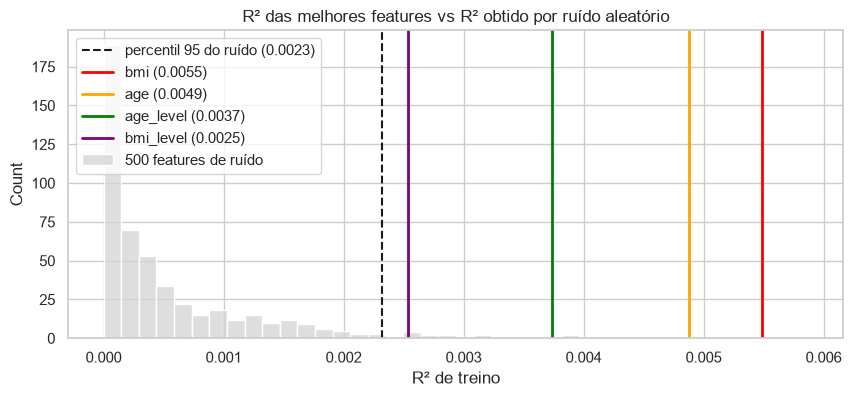

R2 medio do ruido: 0.0006 | percentil 95: 0.0023
Features acima do percentil 95 do ruido (8): ['bmi', 'age', 'age_level', 'bmi_level', 'smoking', 'salt_intake', 'physical_activity', 'triglycerides']


In [7]:
rng = np.random.default_rng(SEED)
noise_r2 = np.array([sm.OLS(y_train, sm.add_constant(rng.normal(size=len(y_train)))).fit().rsquared
                     for _ in range(500)])
p95 = np.percentile(noise_r2, 95)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(noise_r2, bins=40, ax=ax, color='lightgrey', label='500 features de ruído')
ax.axvline(p95, color='k', ls='--', label=f'percentil 95 do ruído ({p95:.4f})')
for f, c in zip(simple.index[:4], ['red', 'orange', 'green', 'purple']):
    ax.axvline(simple.loc[f, 'R2_treino'], color=c, lw=2, label=f'{f} ({simple.loc[f, "R2_treino"]:.4f})')
ax.set_xlabel('R² de treino'); ax.set_title('R² das melhores features vs R² obtido por ruído aleatório'); ax.legend()
plt.show()

real = (simple['R2_treino'] > p95)
print(f'R2 medio do ruido: {noise_r2.mean():.4f} | percentil 95: {p95:.4f}')
print(f'Features acima do percentil 95 do ruido ({real.sum()}):', list(simple.index[real]))

**Conclusões:** as 500 features de ruído atingem, só por acaso, um R² médio de **0.0006**, e 5% delas passam os
**0.0023**. **8 features ficam acima deste limiar**: `bmi` (0.0055), `age` (0.0049), `age_level`, `bmi_level`,
`smoking`, `salt_intake`, `physical_activity` e `triglycerides`.

**Justificação:** o `bmi` explica cerca de **9 vezes** mais variância do que uma feature aleatória típica, e
mais do dobro do percentil 95 do ruído. **A relação é real**, e não um acaso da amostra. Ao mesmo tempo, o
gráfico mostra que todas as features vivem na mesma escala minúscula que o ruído (0 a 0.006). A relação existe,
mas é demasiado fraca para ter utilidade prática.

As restantes 22 features ficam dentro da distribuição do ruído: **não se distinguem de números aleatórios**, o
que coincide com as features "pouco informativas" identificadas na EDA.

### 2.4 Modelo simples escolhido: análise estatística (OLS)

Escolhemos a feature com **menor RMSE em validação cruzada** (tabela 2.2). Analisamo-la com o `statsmodels`, para obter:
- os coeficientes $\hat\beta_0$ e $\hat\beta_1$ e a respetiva **interpretação**;
- o **erro padrão** e o **intervalo de confiança a 95%** de $\hat\beta_1$;
- o **teste *t*** e o p-value.

Calculamos também previsões para pacientes concretos, para dar significado
prático ao coeficiente.

In [8]:
BEST_SIMPLE = simple.index[0]
ols_simple = sm.OLS(y_train, sm.add_constant(X_train[[BEST_SIMPLE]])).fit()
print(f'Feature escolhida: {BEST_SIMPLE}\n')
print(ols_simple.summary().tables[1])
b0, b1 = ols_simple.params
print(f'\nEquacao: target_regression = {b0:.3f} + {b1:.3f} x {BEST_SIMPLE}')
print(f'R2 treino = {ols_simple.rsquared:.4f}\n')
for v in (18.5, 25, 30, 40):
    print(f'  {BEST_SIMPLE} = {v:>4}  ->  previsao = {b0 + b1 * v:.1f}')
print(f'\nAmplitude real do target: {y_train.min():.0f} a {y_train.max():.0f} (desvio padrao {y_train.std():.1f})')

Feature escolhida: bmi

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.0606      4.411     28.353      0.000     116.408     133.713
bmi            0.4254      0.153      2.778      0.006       0.125       0.726

Equacao: target_regression = 125.061 + 0.425 x bmi
R2 treino = 0.0055

  bmi = 18.5  ->  previsao = 132.9
  bmi =   25  ->  previsao = 135.7
  bmi =   30  ->  previsao = 137.8
  bmi =   40  ->  previsao = 142.1

Amplitude real do target: 70 a 300 (desvio padrao 41.4)


**Conclusões — modelo simples escolhido: `bmi`.**

$$\widehat{target} = 125.06 + 0.425 \times bmi$$

- **Interpretação de β₁:** por cada unidade a mais de BMI, o target aumenta em média **0.43 unidades**. O
  intervalo de confiança a 95% é [0.125, 0.726], que não inclui o 0, e o teste *t* dá p = 0.006.
- **Interpretação de β₀:** 125.06 seria o valor previsto para BMI = 0. Não tem significado clínico (ninguém tem
  BMI 0); serve apenas para posicionar a reta.
- **Exemplos de previsão:** um paciente magro (BMI 18.5) tem uma previsão de 132.9 e um paciente com obesidade
  severa (BMI 40) de 142.1. **Uma diferença de 21.5 unidades de BMI muda a previsão em apenas 9 unidades**, num
  target que varia entre 70 e 300 (desvio padrão 41.4).

**Justificação da escolha:** o `bmi` é o melhor em todos os critérios: R² de treino (0.0055), RMSE de CV
(41.309), p-value (0.006), e o único destes com relação claramente acima do ruído (2.3). É também uma medição
contínua, mais informativa do que a sua versão categórica `bmi_level`. A escolha é coerente com a EDA, onde o `bmi`
já era a feature mais correlacionada com o target.

### 2.5 Visualização: valores reais vs previstos

Usamos três gráficos no conjunto de treino:
1. **Dispersão com a reta ajustada**: valores reais (pontos) e a reta $\hat y = \hat\beta_0 + \hat\beta_1 x$;
2. **Distribuição dos valores reais vs previstos**: um bom modelo produz previsões com uma distribuição
   parecida com a dos valores reais;
3. **Erro de previsão** (resíduo) de cada registo.

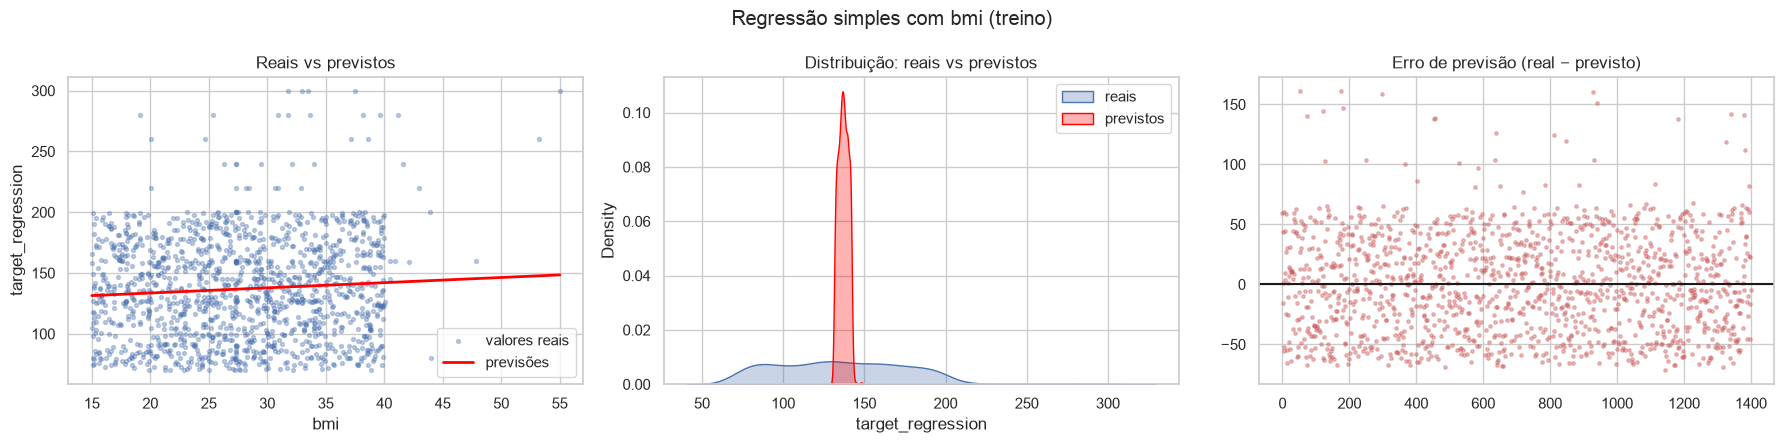

Previsoes: min 131.4, max 148.5, desvio padrao 3.07  |  valores reais: desvio padrao 41.37


In [9]:
pred_simple_train = ols_simple.fittedvalues

def plot_real_vs_pred(x, y_real, y_pred, xlabel, title, line=True):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].scatter(x, y_real, s=8, alpha=.35, label='valores reais')
    if line:
        order = np.argsort(np.asarray(x))
        axes[0].plot(np.asarray(x)[order], np.asarray(y_pred)[order], color='red', lw=2, label='previsões')
    else:
        axes[0].scatter(x, y_pred, s=8, alpha=.5, color='red', label='previsões')
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel('target_regression'); axes[0].legend()
    axes[0].set_title('Reais vs previstos')
    sns.kdeplot(y_real, ax=axes[1], fill=True, alpha=.3, label='reais')
    sns.kdeplot(y_pred, ax=axes[1], fill=True, alpha=.3, color='red', label='previstos')
    axes[1].set_title('Distribuição: reais vs previstos'); axes[1].legend()
    axes[2].scatter(range(len(y_real)), np.asarray(y_real) - np.asarray(y_pred), s=6, alpha=.4, color='indianred')
    axes[2].axhline(0, color='k'); axes[2].set_title('Erro de previsão (real − previsto)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_real_vs_pred(X_train[BEST_SIMPLE], y_train, pred_simple_train, BEST_SIMPLE,
                  f'Regressão simples com {BEST_SIMPLE} (treino)')
print(f'Previsoes: min {pred_simple_train.min():.1f}, max {pred_simple_train.max():.1f}, '
      f'desvio padrao {pred_simple_train.std():.2f}  |  valores reais: desvio padrao {y_train.std():.2f}')

**Conclusões:**
1. **Reais vs previstos:** a reta é quase **horizontal**. Os pontos reais estão espalhados por toda a faixa 70–200,
   para qualquer valor de BMI. Conhecer o BMI de um paciente praticamente não ajuda a adivinhar o seu target.
2. **Distribuição:** o contraste é o resultado mais elucidativo. Os valores reais espalham-se de 70 a 300 (desvio
   padrão **41.4**); as previsões concentram-se num pico estreito entre 131 e 149 (desvio padrão **3.1**). **O
   modelo prevê praticamente o mesmo valor (~137) para todos os pacientes.**
3. **Erro de previsão:** os erros vão de cerca de −65 a +160 e não têm nenhum padrão ao longo dos registos.

**Justificação:** isto é exatamente o que um R² de 0.0055 significa na prática. Quando uma feature quase não
explica o target, a melhor estratégia de mínimos quadrados é prever um valor perto da média para todos. É o mesmo
fenómeno que na classificação: um modelo sem boas features tende a prever sempre a classe maioritária; aqui
tende a prever sempre a média.

### 2.6 Diagnóstico dos resíduos

Problemas a verificar numa regressão linear - Com os resíduos $e_i = y_i - \hat y_i$:
- **Resíduos vs valores previstos**: uma curva indicaria **não-linearidade**; um "funil" indicaria **variância não
  constante** dos erros;
- **Q-Q plot**: compara os resíduos com uma normal. A normalidade dos erros é um pressuposto dos testes *t* e *F*.

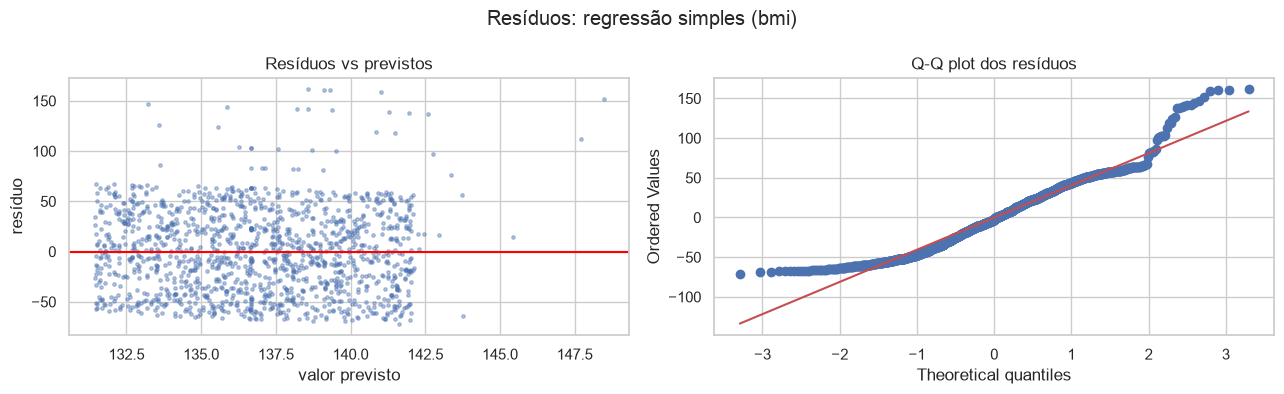

media dos residuos = -0.000 | skew = 0.50
Registos com o target no limite inferior (70): 10 | no limite superior (300): 5


In [10]:
def residual_plots(fitted, resid, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(fitted, resid, s=6, alpha=.4); axes[0].axhline(0, color='red')
    axes[0].set_xlabel('valor previsto'); axes[0].set_ylabel('resíduo'); axes[0].set_title('Resíduos vs previstos')
    stats.probplot(resid, plot=axes[1]); axes[1].set_title('Q-Q plot dos resíduos')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(f'media dos residuos = {np.mean(resid):.3f} | skew = {stats.skew(resid):.2f}')

residual_plots(ols_simple.fittedvalues, ols_simple.resid, f'Resíduos: regressão simples ({BEST_SIMPLE})')
print(f'Registos com o target no limite inferior (70): {(y_train == 70).sum()} | no limite superior (300): {(y_train == 300).sum()}')

**Conclusões:**
- **Resíduos vs previstos:** a nuvem é uma faixa horizontal, sem curvatura nem forma de "funil". **Não há sinais
  de não-linearidade nem de variância não constante.**
- **Q-Q plot:** os resíduos afastam-se da normal nas caudas e têm **assimetria positiva** (skew = 0.50). Isto
  deve-se aos poucos valores muito altos do target (até 300), que geram resíduos positivos grandes. Com n = 1400,
  os testes *t* e *F* continuam aproximadamente válidos (teorema do limite central).
- Há 10 registos no valor mínimo (70) e 5 no máximo (300) do treino. A EDA tinha assinalado esta acumulação nos
  extremos como possível truncatura, mas afeta poucos registos.

**Justificação:** os resíduos não indicam que o modelo tenha a **forma errada**. Indicam que a feature **não tem
informação** suficiente. Mudar a forma do modelo (por exemplo, usar uma curva) não deve resolver o problema; é isso
que testamos a seguir.

### 2.7 Uma relação não-linear seria melhor?

Uma reta pode ser demasiado simples se a relação for curva.
Acrescentando termos polinomiais:
$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots$. Continua a ser regressão **linear** nos coeficientes.

Testamos os graus 1 a 5 com a feature escolhida. Um grau maior aumenta **sempre** o R² de treino, porque o modelo
fica mais flexível. Por isso a escolha tem de ser feita pela **validação cruzada**.

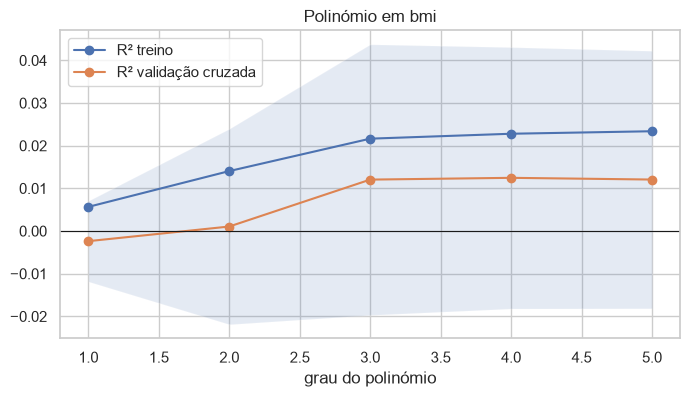

,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
grau,,,,,
1,0.0057,-0.0024,0.0095,33.9732,41.3094
2,0.0141,0.0011,0.0229,33.9041,41.2289
3,0.0216,0.0121,0.0317,33.7601,40.9945
4,0.0228,0.0125,0.0306,33.7529,40.9871
5,0.0234,0.0121,0.0302,33.7660,40.9960


In [11]:
poly = pd.DataFrame({d: cv_scores(make_model(d), [BEST_SIMPLE]) for d in range(1, 6)}).T
poly.index.name = 'grau'

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poly.index, poly['train_r2'], marker='o', label='R² treino')
ax.plot(poly.index, poly['cv_r2'], marker='o', label='R² validação cruzada')
ax.fill_between(poly.index, poly['cv_r2'] - poly['cv_r2_std'], poly['cv_r2'] + poly['cv_r2_std'], alpha=.15)
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('grau do polinómio'); ax.set_title(f'Polinómio em {BEST_SIMPLE}')
ax.legend(); plt.show()
poly

**Conclusões:**
- O **R² de treino sobe sempre** com o grau (0.0057 → 0.0234), como esperado: um polinómio mais flexível ajusta-se
  melhor aos dados com que foi treinado.
- O **R² de CV** também sobe ligeiramente (de −0.002 no grau 1 para ~0.012 nos graus 3–5), e o RMSE de CV desce de
  41.31 para 40.99.
- No entanto, o **desvio padrão entre folds (0.03)** é 2–3 vezes maior que o ganho. Em alguns folds o polinómio é
  melhor, noutros pior.

**Justificação — devemos usar o polinómio?** Não. Há três razões:
1. o ganho não é **robusto**: está dentro da variabilidade normal da validação cruzada;
2. o gráfico 2.5 mostra que quase todos os pacientes têm BMI entre 15 e 40 e só alguns têm valores até ~55. Um
   polinómio de grau 3 ou mais pode "dobrar-se" para acompanhar esses poucos pontos extremos, o que é
   *overfitting* e não uma relação clínica;
3. o enunciado pede uma regressão **linear simples**, e a reta é mais interpretável.

Mantemos o modelo de grau 1.

### Resumo da Regressão Linear Simples

| Pergunta | Resposta | Evidência |
|---|---|---|
| Qual é a melhor feature? | **`bmi`** | Menor RMSE de CV (41.309), maior R² (0.0055), menor p-value (0.006) |
| A relação é real? | **Sim, mas fraquíssima** | 9× o R² médio do ruído; β₁ significativo |
| O modelo é útil para prever? | **Não** | Explica 0.55% da variância; o RMSE desce menos de 0.1 face à baseline; as previsões ficam todas entre 131 e 149 |
| Uma curva seria melhor? | **Não de forma robusta** | Ganho menor que a variabilidade entre folds |
| Faz sentido? | **Sim** | A EDA mostrou r ≈ 0.07 para o `bmi`, o máximo do dataset, e R² = r². O resultado era previsível. |

## 3. Regressão Linear Múltipla

$$\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \hat\beta_2 x_2 + \dots + \hat\beta_p x_p$$

Cada $\beta_j$ mede o efeito de $x_j$ **mantendo as outras features fixas**. A ideia é combinar
várias features fracas na esperança de que, juntas, expliquem mais do que qualquer uma sozinha.

**Estratégia (construção incremental):**
1. Verificar a **colinearidade**, para saber que features não devem entrar juntas (3.1).
2. Construir o modelo **passo a passo**: 1 feature → 2 → 3 → …, e explicar cada ganho ou perda (3.2).
3. Testar **todas as combinações** de 2 e 3 features, para confirmar que a ordem escolhida não deixou nada de
   fora (3.3).
4. Testar **grupos clínicos** de features (3.4).
5. Mostrar o que acontece quando se usam **todas** as features: *overfitting* (3.5).
6. Mostrar o efeito da **colinearidade** nos coeficientes (3.6).
7. Testar variantes (transformação do target, polinómio) e escolher o modelo final (3.7–3.8).

### 3.1 Colinearidade entre features (VIF)

Quando duas features estão muito correlacionadas, o modelo não consegue separar o
efeito de cada uma. Os coeficientes ficam instáveis e podem perder significância.

O **VIF** (*Variance Inflation Factor*) de uma feature é $1/(1-R_j^2)$, onde $R_j^2$ é o R² obtido ao prever essa
feature a partir de todas as outras. Valores de referência: VIF = 1 significa que a feature é independente das
restantes; VIF > 5–10 indica colinearidade problemática.

In [12]:
Xc = sm.add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=FEATURES, name='VIF').sort_values(ascending=False)
print(f'corr(age, age_level) = {X_train.age.corr(X_train.age_level):.3f} | '
      f'corr(bmi, bmi_level) = {X_train.bmi.corr(X_train.bmi_level):.3f}')
vif.to_frame().head(10)

corr(age, age_level) = 0.954 | corr(bmi, bmi_level) = 0.936


,VIF
age_level,11.3724
age,11.3228
bmi_level,8.4259
bmi,8.3254
high_ldl_cholesterol,2.8568
ldl,2.8506
low_hdl_cholesterol,1.4350
hdl,1.4106
employment_status_Unemployed,1.3630
employment_status_Retired,1.3548


**Conclusões:** há **dois pares de features colineares**, os mesmos que a EDA identificou:
- `age` ↔ `age_level`: VIF ≈ 11.3, correlação 0.954;
- `bmi` ↔ `bmi_level`: VIF ≈ 8.4, correlação 0.936.

Há também dois pares fracos: `ldl`/`high_ldl_cholesterol` (VIF ≈ 2.9) e `hdl`/`low_hdl_cholesterol` (≈ 1.4).
**Todas as outras features têm VIF próximo de 1**, ou seja, são praticamente independentes entre si.

**Justificação e decisão:** `age_level` e `bmi_level` são discretizações das variáveis contínuas e contêm a mesma
informação, mas com menos detalhe. Nas combinações seguintes usamos **apenas a versão contínua** (`age`, `bmi`) e
as variáveis originais `hdl`/`ldl` em vez das *flags*. Na secção 3.6 mostramos o que acontece quando esta regra não
é seguida.

### 3.2 Construção incremental: 1, 2, 3, … features

Construímos o modelo acrescentando **uma feature de cada vez**. A ordem segue a **força da relação com o target**
(|r| no treino, secção 2.1), mas usamos só uma versão de cada variável: a contínua (`age`, `bmi`), e não a
discretizada (`age_level`, `bmi_level`), por causa da colinearidade vista em 3.1.

Em cada passo registamos:
- **R² de treino**: sobe *sempre* que se acrescenta uma feature, mesmo que seja ruído, porque o modelo tem mais
  liberdade para se ajustar aos dados;
- **R² ajustado**: $1 - (1-R^2)\frac{n-1}{n-p-1}$. Penaliza o número de features *p* e só sobe se a nova feature
  acrescentar mais do que o esperado por acaso;
- **R², MAE e RMSE em validação cruzada**: dizem se o modelo melhora em dados novos.

**O que procuramos:** o ponto a partir do qual acrescentar features deixa de reduzir o erro de validação.

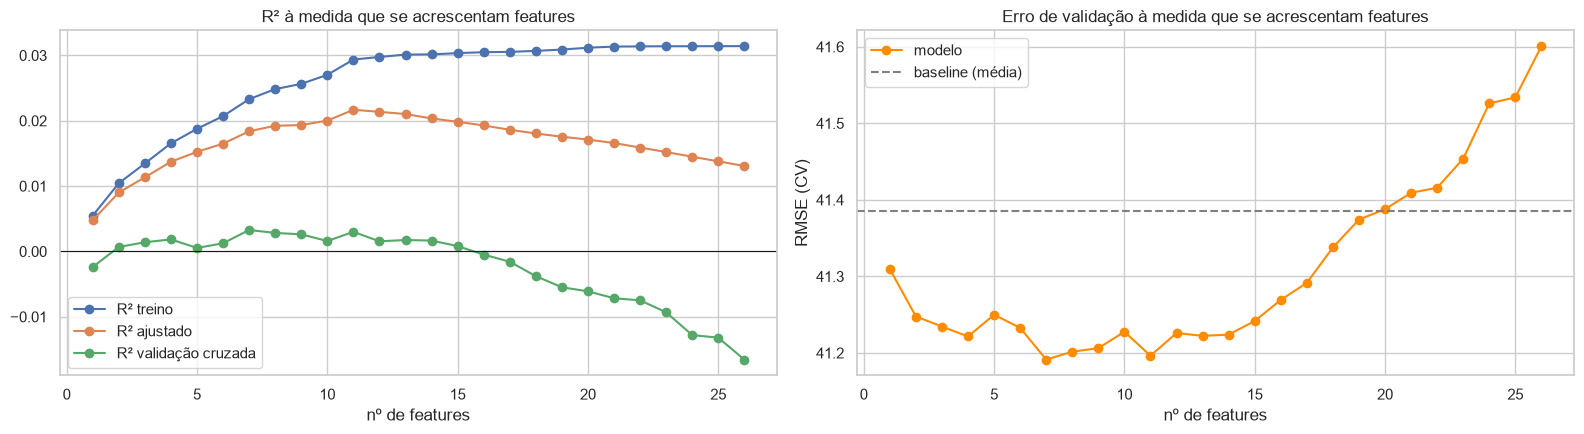

,feature adicionada,r da feature,R2_treino,R2_ajustado,cv_r2,cv_mae,cv_rmse
n,,,,,,,
1,bmi,0.0741,0.0055,0.0048,-0.0024,33.9732,41.3094
2,age,0.0699,0.0104,0.0090,0.0007,33.8505,41.2475
3,smoking,-0.0603,0.0135,0.0113,0.0014,33.8462,41.2344
4,salt_intake,-0.0568,0.0165,0.0137,0.0018,33.7758,41.2214
5,triglycerides,0.0530,0.0188,0.0152,0.0005,33.8280,41.2498
6,physical_activity,0.0496,0.0207,0.0165,0.0012,33.8581,41.2326
7,HbA1c_level,0.0437,0.0233,0.0184,0.0033,33.9333,41.1912
8,hdl,-0.0374,0.0248,0.0192,0.0028,33.9264,41.2016
9,crp_level,0.0372,0.0256,0.0193,0.0026,33.9272,41.2061


In [13]:
order = [f for f in r_train.abs().sort_values(ascending=False).index
         if f not in ('age_level', 'bmi_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol')]
rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]
    ols = sm.OLS(y_train, sm.add_constant(X_train[cols].astype(float))).fit()
    cv = cv_scores(make_model(), cols)
    rows.append({'n': k, 'feature adicionada': cols[-1], 'r da feature': r_train[cols[-1]],
                 'R2_treino': ols.rsquared, 'R2_ajustado': ols.rsquared_adj,
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
incremental = pd.DataFrame(rows).set_index('n')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(incremental.index, incremental['R2_treino'], marker='o', label='R² treino')
axes[0].plot(incremental.index, incremental['R2_ajustado'], marker='o', label='R² ajustado')
axes[0].plot(incremental.index, incremental['cv_r2'], marker='o', label='R² validação cruzada')
axes[0].axhline(0, color='k', lw=.8); axes[0].set_xlabel('nº de features'); axes[0].legend()
axes[0].set_title('R² à medida que se acrescentam features')
axes[1].plot(incremental.index, incremental['cv_rmse'], marker='o', color='darkorange', label='modelo')
axes[1].axhline(baseline_cv['cv_rmse'], color='grey', ls='--', label='baseline (média)')
axes[1].set_xlabel('nº de features'); axes[1].set_ylabel('RMSE (CV)'); axes[1].legend()
axes[1].set_title('Erro de validação à medida que se acrescentam features')
plt.tight_layout(); plt.show()
incremental.head(12)

**Conclusões passo a passo:**

| Passo | O que acontece | Porquê |
|---|---|---|
| **1 → 2** (`bmi` + `age`) | O R² de CV passa de −0.002 para **0.001** (primeiro valor positivo) e o RMSE desce de 41.31 para 41.25. **É o maior ganho de toda a construção.** | `age` é a 2.ª feature mais correlacionada com o target (r = 0.070) e é **independente** do `bmi` (correlação −0.007). Por isso traz informação nova: os contributos somam-se (R² de treino 0.0055 + 0.0049 ≈ 0.0104). |
| **2 → 4** (+ `smoking`, + `salt_intake`) | Pequenas melhorias: RMSE 41.23 → 41.22. | Features com r ≈ −0.06, também independentes das anteriores. Cada uma acrescenta ~0.3% de R² de treino. |
| **5** (+ `triglycerides`) | O RMSE de CV **sobe** (41.25). | A feature ajuda no treino, mas não generaliza: o contributo que dá no treino é, em parte, ruído. |
| **7** (+ `HbA1c_level`) | **Melhor RMSE de CV: 41.191.** | `HbA1c_level` tem r baixo no treino (0.044), mas combinado com as restantes melhora a validação. |
| **8 → 12** | O RMSE de CV oscila entre 41.20 e 41.23, sem melhorar. | As features novas têm r < 0.04: estão ao nível do ruído (secção 2.3). |

**O padrão geral (gráfico):**
- o **R² de treino sobe sempre** (0.0055 → 0.0298 com 12 features), porque cada feature dá ao modelo mais
  liberdade para se ajustar aos dados de treino, mesmo que seja ruído;
- o **R² ajustado** sobe cada vez mais devagar, porque penaliza o número de features;
- o **R² de CV estabiliza à volta de 0.002–0.003** a partir de 4 features e depois oscila. O RMSE de CV nunca desce
  mais do que ~0.2 abaixo da baseline.

**Justificação:** a diferença crescente entre o R² de treino e o R² de CV é a definição de *overfitting*. As
primeiras features (`bmi`, `age`) trazem informação real; as seguintes trazem sobretudo ruído, que melhora o treino
mas não os dados novos.

### 3.3 Todas as combinações de 2 e de 3 features

A construção incremental seguiu uma ordem fixa (a do |r|), mas pode acontecer que duas features individualmente
fracas funcionem bem em conjunto. Para confirmar, testamos **todas** as combinações de 2 e de 3 features entre as
12 melhores features contínuas/ordinais (66 pares e 220 trios), avaliadas por validação cruzada.

Mostramos as 5 melhores e as 3 piores de cada tamanho, para perceber **o que distingue uma boa combinação de uma
má.**

In [14]:
pool = order[:12]
combo_rows = []
for size in (2, 3):
    for cols in combinations(pool, size):
        cv = cv_scores(make_model(), list(cols))
        combo_rows.append({'n': size, 'features': ' + '.join(cols), 'cv_r2': cv['cv_r2'],
                           'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
combos_df = pd.DataFrame(combo_rows)
for size in (2, 3):
    sub = combos_df[combos_df.n == size].sort_values('cv_rmse')
    print(f'\n=== {size} features: {len(sub)} combinacoes | {(sub.cv_rmse < baseline_cv["cv_rmse"]).sum()} melhores que a baseline ===')
    display(pd.concat([sub.head(5), sub.tail(3)]).set_index('features'))
print(f'corr(bmi, age) no treino = {X_train.bmi.corr(X_train.age):.3f}')


=== 2 features: 66 combinacoes | 53 melhores que a baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age,2,0.0007,33.8505,41.2475
bmi + HbA1c_level,2,-0.0008,34.0375,41.2767
age + HbA1c_level,2,-0.0009,33.8854,41.2838
bmi + physical_activity,2,-0.0014,34.0030,41.2866
bmi + smoking,2,-0.0012,33.9500,41.2876
alcohol_intake + family_history,2,-0.0070,33.9994,41.4069
hdl + family_history,2,-0.0073,33.9676,41.4131
hdl + alcohol_intake,2,-0.0073,33.9550,41.4162



=== 3 features: 220 combinacoes | 188 melhores que a baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age + HbA1c_level,3,0.0026,33.9074,41.2080
bmi + age + blood_pressure,3,0.0022,33.8227,41.2136
bmi + age + smoking,3,0.0014,33.8462,41.2344
bmi + age + physical_activity,3,0.0011,33.8761,41.2360
bmi + age + salt_intake,3,0.0010,33.7757,41.2369
triglycerides + hdl + alcohol_intake,3,-0.0075,34.0138,41.4196
triglycerides + hdl + family_history,3,-0.0078,34.0234,41.4255
hdl + alcohol_intake + family_history,3,-0.0080,33.9871,41.4295


corr(bmi, age) no treino = -0.007


**Conclusões:**
- **Melhor par: `bmi` + `age`** (RMSE de CV 41.248). **Melhor trio: `bmi` + `age` + `HbA1c_level`** (41.208),
  seguido de `bmi` + `age` + `blood_pressure` (41.214).
- **Os 5 melhores pares e os 5 melhores trios contêm todos o `bmi`**, e todos os melhores trios contêm `bmi` e
  `age`.
- **As piores combinações** juntam `hdl`, `alcohol_intake`, `family_history` e `triglycerides` (RMSE ≈ 41.41–41.43,
  **pior que a baseline**).
- Ainda assim, 53 dos 66 pares e 188 dos 220 trios ficam (muito ligeiramente) abaixo da baseline.

**Justificação — porque é que umas combinações dão menos erro que outras?**
1. **Uma combinação é tão boa quanto as features que a compõem.** `bmi` e `age` são as duas features com maior |r|
   e as únicas claramente acima do ruído em 2.3. Qualquer combinação sem elas perde.
2. **As features devem trazer informação diferente.** `bmi` e `age` têm correlação −0.007 entre si: cada uma
   explica uma parte diferente da variância do target, e os efeitos somam-se. Juntar duas features correlacionadas
   (como `bmi` e `bmi_level`) não acrescenta nada, porque repetem a mesma informação.
3. **Juntar features sem relação com o target piora o modelo.** As piores combinações são formadas por features ao
   nível do ruído. O modelo estima coeficientes para elas a partir de padrões aleatórios do treino, que não se
   repetem nos dados de validação, e o erro aumenta.

A pesquisa exaustiva confirma a ordem da construção incremental: não há nenhum par ou trio "escondido" que
funcione melhor do que as combinações com `bmi` e `age`.

### 3.4 Grupos clínicos de features

Outra forma de escolher combinações é usar **conhecimento do domínio**: agrupar as features pelo tipo de
informação clínica que representam e ver se algum grupo, no seu conjunto, explica o target. Se o target fosse, por
exemplo, um marcador lipídico, o grupo lipídico deveria destacar-se.

In [15]:
GROUPS = {
    'Antropométrico (age, bmi)':              ['age', 'bmi'],
    'Antropométrico + glicémico':             ['age', 'bmi', 'HbA1c_level'],
    'Glicémico (HbA1c)':                      ['HbA1c_level'],
    'Lipídico':                               ['cholesterol', 'triglycerides', 'hdl', 'ldl'],
    'Pressão arterial / cardíaco':            ['systolic_bp', 'diastolic_bp', 'blood_pressure', 'heart_rate'],
    'Inflamatório':                           ['crp_level', 'homocysteine_level', 'plasma_value'],
    'Estilo de vida':                         ['smoking', 'physical_activity', 'stress_level', 'sugar_consumption',
                                               'sleep_hours', 'alcohol_intake', 'salt_intake'],
    'Sociodemográfico':                       ['gender', 'education_level', 'family_history',
                                               'employment_status_Retired', 'employment_status_Unemployed'],
    'Todas as numéricas contínuas':           CONTINUOUS,
}
groups = pd.DataFrame({g: {'n_features': len(c), **cv_scores(make_model(), c)} for g, c in GROUPS.items()}).T
groups['melhor que baseline?'] = groups['cv_rmse'] < baseline_cv['cv_rmse']
groups.sort_values('cv_rmse')

,n_features,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse,melhor que baseline?
Antropométrico + glicémico,3.0000,0.0131,0.0026,0.0091,33.9074,41.2080,True
"Antropométrico (age, bmi)",2.0000,0.0108,0.0007,0.0096,33.8505,41.2475,True
Glicémico (HbA1c),1.0000,0.0020,-0.0043,0.0043,34.0091,41.3526,True
Todas as numéricas contínuas,17.0000,0.0291,-0.0056,0.0174,33.9903,41.3733,True
Estilo de vida,7.0000,0.0121,-0.0071,0.0135,33.9405,41.4047,False
Lipídico,4.0000,0.0058,-0.0073,0.0126,33.9931,41.4164,False
Inflamatório,3.0000,0.0018,-0.0085,0.0073,33.9810,41.4390,False
Pressão arterial / cardíaco,4.0000,0.0020,-0.0105,0.0058,34.0077,41.4768,False
Sociodemográfico,5.0000,0.0025,-0.0135,0.0045,34.0732,41.5417,False


**Conclusões:**
- Só **4 grupos** ficam abaixo da baseline: **antropométrico + glicémico** (RMSE 41.208), antropométrico (41.248),
  glicémico (41.353) e, por muito pouco, todas as numéricas contínuas (41.373 contra 41.385).
- Os grupos **lipídico, pressão arterial, inflamatório, estilo de vida e sociodemográfico ficam todos acima da
  baseline**: prevêem pior do que a média.
- O grupo com **todas as 17 numéricas contínuas** tem o maior R² de treino (0.029), mas em validação cruzada fica
  praticamente igual à baseline (41.373 contra 41.385). O pouco sinal de `age` e `bmi` é quase todo anulado pelo
  ruído das outras 15 features.

**Justificação:** um grupo funciona se contiver features relacionadas com o target. Os grupos vencedores são os
que incluem `age` e `bmi`, as únicas com sinal real. Os outros grupos são formados por features com r ≈ 0 (EDA,
secção 3.4) e, sem nada para aprender, só acrescentam ruído.

O mau desempenho do grupo lipídico é informativo: **não há evidência de que o target seja um marcador lipídico**,
porque colesterol, triglicéridos, HDL e LDL não o explicam. O mesmo vale para a pressão arterial e a inflamação. O
nome e as unidades do target continuam desconhecidos.

### 3.5 E se usarmos todas as features? *Overfitting*

A tentação natural é "pôr tudo no modelo". Ajustamos a regressão com as 30 features e comparamos o desempenho no
**treino** com o desempenho em **validação cruzada**. Uma diferença grande entre os dois é o sinal clássico de
***overfitting***: o modelo ajusta-se ao ruído específico dos dados de treino, que não se repete em dados novos.

In [16]:
ols_all = sm.OLS(y_train, sm.add_constant(X_train.astype(float))).fit()
cv_all = cv_scores(make_model(), FEATURES)
print(f'R2 treino = {ols_all.rsquared:.4f} | R2 ajustado = {ols_all.rsquared_adj:.4f} | '
      f'teste F: F = {ols_all.fvalue:.2f}, p = {ols_all.f_pvalue:.4f}')
print(f'CV: R2 = {cv_all["cv_r2"]:.4f} | MAE = {cv_all["cv_mae"]:.3f} | RMSE = {cv_all["cv_rmse"]:.3f}')
print(f'Baseline CV RMSE = {baseline_cv["cv_rmse"]:.3f}')
sig = ols_all.pvalues.drop('const')
print(f'\nCoeficientes com p < 0.05: {list(sig[sig < 0.05].index)}')

R2 treino = 0.0370 | R2 ajustado = 0.0159 | teste F: F = 1.75, p = 0.0073
CV: R2 = -0.0261 | MAE = 34.201 | RMSE = 41.793
Baseline CV RMSE = 41.385

Coeficientes com p < 0.05: ['bmi_level', 'bmi', 'triglycerides', 'salt_intake']


**Conclusões:** com as 30 features:
- o **R² de treino é o mais alto de todos (0.0370)** e o teste *F* é significativo (p = 0.007);
- mas o **R² de CV é −0.026** e o RMSE de CV é **41.79, claramente pior que a baseline (41.38)**;
- o R² ajustado (0.0159) é mais baixo que o de modelos com menos features (secção 3.2);
- 4 coeficientes são significativos: `bmi_level`, `bmi`, `triglycerides` e `salt_intake`. Dois deles são o par
  colinear `bmi`/`bmi_level`, cujos coeficientes ficam distorcidos (ver 3.6).

**Justificação:** isto é ***overfitting***. Com 30 coeficientes para estimar e quase nenhum sinal real, o modelo
usa a sua flexibilidade para se ajustar a padrões aleatórios do treino. Esses padrões não existem nos dados de
validação, por isso **o modelo com mais features é o que pior generaliza**.

É também um bom exemplo de que um teste *F* significativo não garante um modelo útil: o teste diz que pelo menos
um coeficiente é diferente de zero, não que o modelo prevê bem.

### 3.6 O efeito da colinearidade nos coeficientes

Para mostrar na prática o problema identificado em 3.1, comparamos o coeficiente de `bmi` em dois modelos:
- só com `bmi`;
- com `bmi` **e** `bmi_level` (a sua versão discretizada, VIF ≈ 8).

Se a colinearidade for um problema, o erro padrão do coeficiente aumenta e o p-value piora, **sem que o modelo
preveja melhor**.

In [17]:
m1 = sm.OLS(y_train, sm.add_constant(X_train[['bmi']])).fit()
m2 = sm.OLS(y_train, sm.add_constant(X_train[['bmi', 'bmi_level']])).fit()
colin = pd.DataFrame({
    'so bmi':            {'coef bmi': m1.params['bmi'], 'erro padrao bmi': m1.bse['bmi'], 'p-value bmi': m1.pvalues['bmi'],
                          'R2 treino': m1.rsquared, 'CV RMSE': cv_scores(make_model(), ['bmi'])['cv_rmse']},
    'bmi + bmi_level':   {'coef bmi': m2.params['bmi'], 'erro padrao bmi': m2.bse['bmi'], 'p-value bmi': m2.pvalues['bmi'],
                          'R2 treino': m2.rsquared, 'CV RMSE': cv_scores(make_model(), ['bmi', 'bmi_level'])['cv_rmse']},
}).T
colin

,coef bmi,erro padrao bmi,p-value bmi,R2 treino,CV RMSE
so bmi,0.4254,0.1531,0.0055,0.0055,41.3094
bmi + bmi_level,1.2453,0.4343,0.0042,0.0084,41.3448


**Conclusões:**
- **Só `bmi`:** coeficiente 0.425, erro padrão 0.153.
- **`bmi` + `bmi_level`:** o coeficiente do `bmi` **quase triplica** (1.245) e o erro padrão também (0.434).
  O R² de treino sobe um pouco (0.0055 → 0.0084), mas o **RMSE de CV piora** (41.31 → 41.34).

**Justificação:** como `bmi` e `bmi_level` medem o mesmo (correlação 0.936), o modelo não consegue separar o efeito
de cada uma. O coeficiente do `bmi` deixa de significar "efeito de uma unidade de BMI", porque passa a ser
compensado pelo coeficiente de `bmi_level` em sentido contrário. Os coeficientes ficam **instáveis e
inflacionados**, sem nenhum ganho de previsão. Isto confirma a decisão de
usar apenas as variáveis contínuas.

### 3.7 Variantes: transformação do target e termos polinomiais

Testamos duas ideias, aplicadas à melhor combinação encontrada até aqui:
1. **`log1p(target)`**: reduz a assimetria do target. As métricas são calculadas
   de volta na escala original, para serem comparáveis;
2. **Polinómio de grau 2**: acrescenta os quadrados e os produtos entre features
   (interações).

In [18]:
best_combo_row = combos_df.sort_values('cv_rmse').iloc[0]
best_inc_n = incremental['cv_rmse'].idxmin()
candidates_multi = {
    f'Incremental (melhor n = {best_inc_n})': order[:best_inc_n],
    f'Melhor combinação ({best_combo_row.features})': best_combo_row.features.split(' + '),
}
BEST_MULTI_NAME = min(candidates_multi, key=lambda k: cv_scores(make_model(), candidates_multi[k])['cv_rmse'])
BEST_MULTI = candidates_multi[BEST_MULTI_NAME]
print('Candidatos:'); [print(f'  {k}: {v}') for k, v in candidates_multi.items()]
print(f'Base para as variantes: {BEST_MULTI_NAME}\n')

log_model = TransformedTargetRegressor(regressor=make_model(), func=np.log1p, inverse_func=np.expm1)
variants = pd.DataFrame({
    'linear':                cv_scores(make_model(), BEST_MULTI),
    'log1p(target)':         cv_scores(log_model, BEST_MULTI),
    'polinómio grau 2':      cv_scores(make_model(2), BEST_MULTI),
}).T
print(f'skew do target: {y_train.skew():.2f} -> skew de log1p(target): {np.log1p(y_train).skew():.2f}')
variants

Candidatos:
  Incremental (melhor n = 7): ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']
  Melhor combinação (bmi + age + HbA1c_level): ['bmi', 'age', 'HbA1c_level']
Base para as variantes: Incremental (melhor n = 7)



skew do target: 0.53 -> skew de log1p(target): -0.16


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
linear,0.0248,0.0033,0.0105,33.9333,41.1912
log1p(target),0.0033,-0.0176,0.0291,33.9824,41.6151
polinómio grau 2,0.0768,0.0117,0.0221,34.0876,41.0132


**Conclusões:** as duas candidatas a modelo múltiplo eram:
- **incremental com 7 features** (RMSE de CV 41.191);
- **o melhor trio** `bmi` + `age` + `HbA1c_level` (41.208).

A de 7 features tem o menor erro e foi usada como base para as variantes:
- **`log1p(target)`:** reduz a assimetria do target (0.53 → −0.16), mas **piora** o modelo (RMSE de CV 41.62, R² de
  CV −0.018);
- **polinómio de grau 2:** sobe o R² de CV para 0.012 e baixa o RMSE para 41.01, mas **piora o MAE** (34.09 vs
  33.93). Com 7 features, passa de 7 para 35 termos e o R² de treino triplica (0.077): sinal de *overfitting*.

**Justificação:**
- No exemplo Boston Housing, o `log1p` ajudava porque havia relações fortes, que ficavam mais lineares na escala
  logarítmica. Aqui o problema não é a forma da distribuição: é a falta de informação nas features. O log
  comprime os valores altos, e o modelo passa a subestimá-los ainda mais.
- O ganho do polinómio é menor que o desvio padrão entre folds (0.022) e não se confirma no MAE. Não é robusto.

**Decisão:** manter a regressão **linear**.

### 3.8 Modelo múltiplo escolhido: análise estatística e visualização

Analisamos o modelo escolhido com o `statsmodels`:
- **teste *F*** do modelo global, $H_0: \beta_1 = \dots = \beta_p = 0$, que responde à questão (alguma feature é útil?);
- **teste *t*** de cada coeficiente;
- os mesmos gráficos de valores reais vs previstos e de resíduos usados na regressão simples.

Features: ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                93.2643     15.300      6.096      0.000      63.251     123.277
bmi                   0.3983      0.152      2.615      0.009       0.100       0.697
age                   0.1388      0.054      2.580      0.010       0.033       0.244
smoking              -2.4445      1.338     -1.828      0.068      -5.068       0.179
salt_intake          -0.6715      0.314     -2.141      0.032      -1.287      -0.056
triglycerides         0.0343      0.017      2.021      0.043       0.001       0.068
physical_activity     2.1089      1.349      1.563      0.118      -0.538       4.756
HbA1c_level           3.7061      1.927      1.923      0.055      -0.075       7.487

R2 treino = 0.0233 | R2 ajustado =

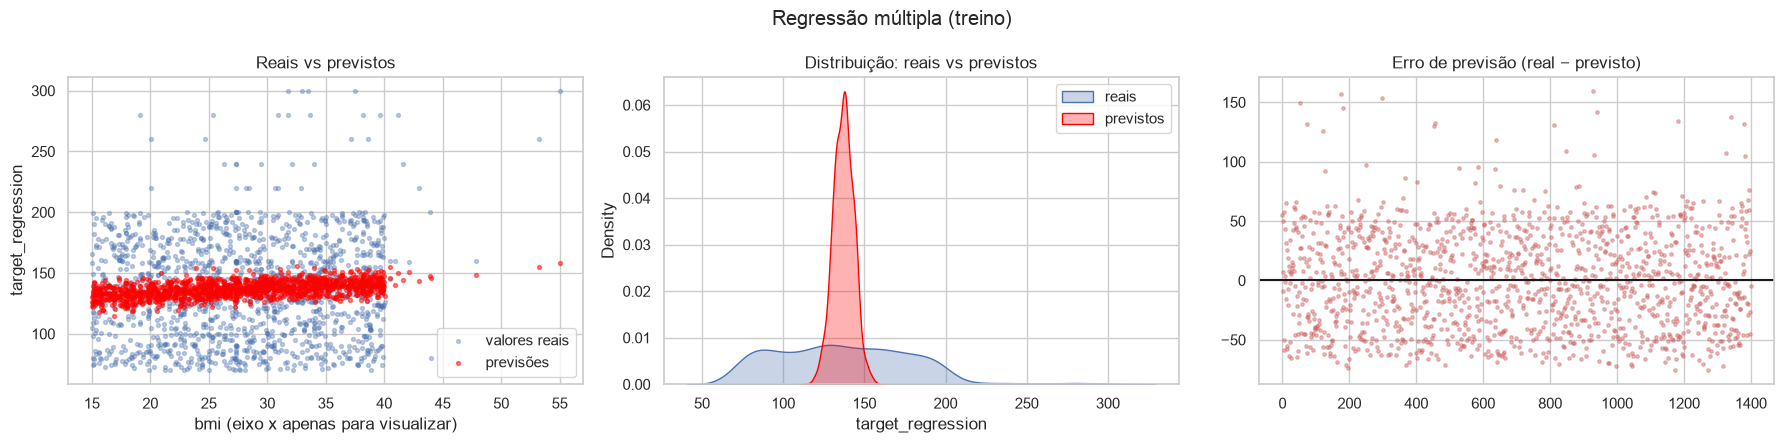

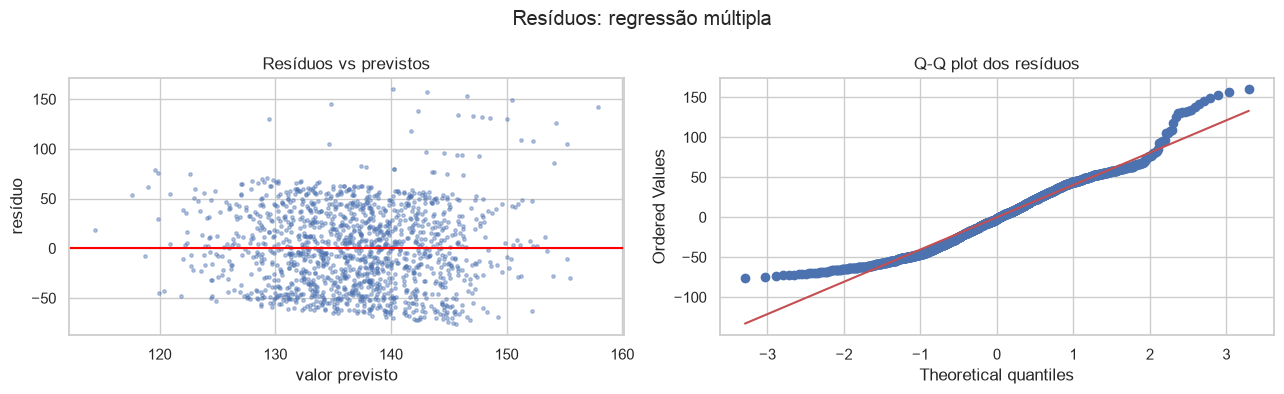

media dos residuos = 0.000 | skew = 0.43
Previsoes: min 114.4, max 157.9, desvio padrao 6.32


In [19]:
ols_multi = sm.OLS(y_train, sm.add_constant(X_train[BEST_MULTI].astype(float))).fit()
print(f'Features: {BEST_MULTI}\n')
print(ols_multi.summary().tables[1])
print(f'\nR2 treino = {ols_multi.rsquared:.4f} | R2 ajustado = {ols_multi.rsquared_adj:.4f}')
print(f'Teste F global: F = {ols_multi.fvalue:.3f}, p = {ols_multi.f_pvalue:.2e}')
eq = ' '.join(f'{v:+.3f} x {k}' for k, v in ols_multi.params.drop('const').items())
print(f'\nEquacao: target_regression = {ols_multi.params["const"]:.3f} {eq}')

plot_real_vs_pred(X_train['bmi'], y_train, ols_multi.fittedvalues, 'bmi (eixo x apenas para visualizar)',
                  'Regressão múltipla (treino)', line=False)
residual_plots(ols_multi.fittedvalues, ols_multi.resid, 'Resíduos: regressão múltipla')
print(f'Previsoes: min {ols_multi.fittedvalues.min():.1f}, max {ols_multi.fittedvalues.max():.1f}, '
      f'desvio padrao {ols_multi.fittedvalues.std():.2f}')

**Conclusões — modelo múltiplo escolhido: construção incremental com 7 features.**

$$\widehat{target} = 93.26 + 0.398\,bmi + 0.139\,age - 2.44\,smoking - 0.672\,salt + 0.034\,trig + 2.11\,phys.act + 3.71\,HbA1c$$

- **Teste *F* global:** F = 4.74, p = 2.8×10⁻⁵. Rejeitamos $H_0$ (todos os β = 0): as features, em conjunto, têm
  relação estatística com o target.
- **Coeficientes significativos (p < 0.05):** `bmi` (+0.40 por unidade), `age` (+0.14 por ano), `salt_intake`
  (−0.67) e `triglycerides` (+0.034). `HbA1c_level` (p = 0.055) e `smoking` (p = 0.068) ficam na fronteira;
  `physical_activity` não é significativo (p = 0.12).
- Os coeficientes de `bmi` (0.398) e `age` (0.139) são praticamente iguais aos dos modelos simples (0.425 e 0.141).
  Isto confirma que as features são independentes (VIF ≈ 1): juntá-las não altera o efeito de cada uma.
- **R² de treino = 0.023 (ajustado 0.018):** o modelo explica cerca de **2%** da variância, 4 vezes mais que a
  regressão simples, mas continua muito baixo.

**Visualização:** as previsões espalham-se um pouco mais que as do modelo simples (114–158, desvio padrão 6.3, contra
3.1), mas continuam muito concentradas face aos valores reais (desvio padrão 41.4). Os resíduos mantêm o mesmo
comportamento: sem padrão, com assimetria positiva (skew = 0.43).

**Interpretação clínica: cautela.** Alguns sinais não são os esperados clinicamente (por exemplo, mais sal associado
a um target *menor*). Como os efeitos são minúsculos e o target é desconhecido, **não devemos tirar conclusões
clínicas** destes coeficientes.

**Justificação da escolha:** é a combinação com menor RMSE de CV (41.191). Em alternativa, o trio `bmi` + `age` +
`HbA1c_level` tem um erro quase igual (41.208), com menos de metade das features. A diferença entre os dois (0.017)
é muito menor que a variabilidade entre folds, por isso o trio seria uma escolha igualmente defensável pelo
princípio da parcimónia (preferir o modelo mais simples quando o desempenho é equivalente).

### Resumo da Regressão Linear Múltipla

| Pergunta | Resposta | Evidência |
|---|---|---|
| Juntar features ajuda? | **Um pouco, até ~4–7 features** | RMSE de CV 41.31 (1 feature) → 41.19 (7) |
| Qual é o melhor grupo? | **`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level`** | Menor RMSE de CV entre construção incremental, 286 combinações e 9 grupos clínicos |
| Porque é que `bmi` + `age` é o melhor par? | São as 2 features com mais sinal **e** são independentes entre si | r = 0.074 e 0.070; correlação entre ambas −0.007 |
| E com todas as features? | **Pior que a baseline** | *Overfitting*: R² de treino 0.0370, R² de CV −0.026 |
| Usar contínua + discretizada? | **Não** | Coeficientes instáveis e inflacionados, sem ganho de previsão |
| Faz sentido? | **Sim** | Combinar features fracas e independentes soma R² pequenos (0.0055 + 0.0049 + …), mas o total fica em ~2% |

## 4. Avaliação final no conjunto de teste

Com todas as escolhas fechadas **usando apenas o treino**, avaliamos agora os modelos no teste (600 registos
nunca usados). É esta avaliação que responde ao enunciado: *"Evaluate both models using appropriate metrics
(R², MAE, RMSE)"*.

Comparamos quatro modelos:
- **Baseline** (média do treino), a referência mínima;
- **Regressão simples** escolhida na secção 2;
- **Regressão múltipla** escolhida na secção 3;
- **Regressão com todas as features**, apenas para confirmar o *overfitting* (não é um modelo escolhido).

### 4.1 Métricas no teste

Cada modelo é treinado em todo o conjunto de treino e avaliado no teste. Mostramos as métricas de treino ao lado
das de teste: a diferença entre as duas mostra quanto cada modelo perde ao passar para dados novos.

In [20]:
final_models = {
    'Baseline (média)':                        (DummyRegressor(strategy='mean'), FEATURES),
    f'Simples ({BEST_SIMPLE})':                 (make_model(), [BEST_SIMPLE]),
    f'Múltipla ({" + ".join(BEST_MULTI)})':     (make_model(), BEST_MULTI),
    f'Todas as features ({len(FEATURES)})':     (make_model(), FEATURES),
}
preds, rows = {}, {}
for name, (model, cols) in final_models.items():
    model.fit(X_train[cols], y_train)
    preds[name] = model.predict(X_test[cols])
    rows[name] = {**{f'treino_{k}': v for k, v in metrics(y_train, model.predict(X_train[cols])).items()},
                  **{f'teste_{k}': v for k, v in metrics(y_test, preds[name]).items()}}
results = pd.DataFrame(rows).T
names = list(preds)
results

,treino_R2,treino_MAE,treino_RMSE,teste_R2,teste_MAE,teste_RMSE
Baseline (média),0.0000,33.9128,41.3560,-0.0058,34.2872,41.0163
Simples (bmi),0.0055,33.9046,41.2423,-0.0024,34.1833,40.9479
Múltipla (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),0.0233,33.6568,40.8713,0.0045,34.1100,40.8067
Todas as features (30),0.0370,33.2981,40.5832,-0.0180,34.3145,41.2641


**Conclusões — resultados no teste (600 pacientes nunca vistos):**

| Modelo | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (média) | −0.006 | 34.29 | 41.02 |
| Simples (`bmi`) | −0.002 | 34.18 | 40.95 |
| **Múltipla (7 features)** | **0.005** | **34.11** | **40.81** |
| Todas as features (30) | −0.018 | 34.31 | 41.26 |

- **A regressão múltipla é a melhor nas três métricas**, seguida da simples e da baseline. **A ordem é a mesma que
  em validação cruzada**: as escolhas feitas só com o treino generalizaram de forma coerente.
- O modelo com todas as features é **o pior**, abaixo da baseline. Tem o maior R² de treino (0.0370) e o menor de
  teste (−0.018), o que confirma o *overfitting* detetado em 3.5.
- As melhorias são **muito pequenas**: a múltipla erra em média **34.11** contra **34.29** da baseline, menos 0.18
  unidades (**0.5%**).
- Em todos os modelos o R² de teste é menor que o de treino, como esperado.

### 4.2 As diferenças entre modelos são reais? (*bootstrap*)

As diferenças da tabela anterior podem ser pequenas. Para saber se são reais ou fruto do acaso (de quais pacientes
calharam no teste), usamos ***bootstrap***: reamostramos o conjunto de teste 1000 vezes, com reposição, e
recalculamos as métricas em cada reamostra. Obtemos assim um **intervalo de confiança a 95%** para cada métrica e
para a diferença entre modelos.

Se o intervalo da diferença entre um modelo e a baseline incluir o zero, **não podemos afirmar que o modelo é
melhor que prever a média**.

In [21]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))

boot = {}
for name, p in preds.items():
    r2s = [r2_score(yt[i], p[i]) for i in idx]; rm = [rmse(yt[i], p[i]) for i in idx]
    boot[name] = {'R2 IC95%': f'[{np.percentile(r2s, 2.5):.3f}, {np.percentile(r2s, 97.5):.3f}]',
                  'RMSE IC95%': f'[{np.percentile(rm, 2.5):.2f}, {np.percentile(rm, 97.5):.2f}]'}
for name in names[1:]:
    d = [rmse(yt[i], preds[name][i]) - rmse(yt[i], preds[names[0]][i]) for i in idx]
    boot[name]['dif. RMSE vs baseline (IC95%)'] = f'{np.mean(d):+.3f}  [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]'
pd.DataFrame(boot).T.fillna('—')

,R2 IC95%,RMSE IC95%,dif. RMSE vs baseline (IC95%)
Baseline (média),"[-0.026, -0.000]","[38.63, 43.29]",—
Simples (bmi),"[-0.026, 0.011]","[38.60, 43.19]","-0.065 [-0.292, +0.153]"
Múltipla (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),"[-0.031, 0.032]","[38.52, 42.96]","-0.194 [-0.742, +0.322]"
Todas as features (30),"[-0.057, 0.013]","[38.91, 43.44]","+0.256 [-0.369, +0.867]"


**Conclusões:**
- Os intervalos de confiança do RMSE **sobrepõem-se quase totalmente**: todos os modelos ficam entre ~38.5 e ~43.5.
- **Diferença de RMSE face à baseline:**
  - simples: −0.065, IC95% **[−0.29, +0.15]**;
  - múltipla: −0.194, IC95% **[−0.74, +0.32]**;
  - todas as features: +0.256, IC95% [−0.37, +0.87].
- **Todos os intervalos incluem o zero.**

**Justificação:** como o zero está dentro de todos os intervalos, **não podemos afirmar, com 95% de confiança,
que algum modelo é melhor do que prever a média**. As pequenas vantagens da tabela 4.1 podem resultar de quais
pacientes calharam no conjunto de teste. Com outra divisão treino/teste, a ordem poderia mudar.

### 4.3 Visualização da comparação

Dois tipos de gráfico:
1. **Barras com R², MAE e RMSE no teste**, para comparar os modelos diretamente;
2. **Valores previstos vs reais no teste.** Num modelo perfeito, todos os pontos ficariam sobre a diagonal
   vermelha. Num modelo que não aprende nada, os pontos formam uma linha horizontal na média.

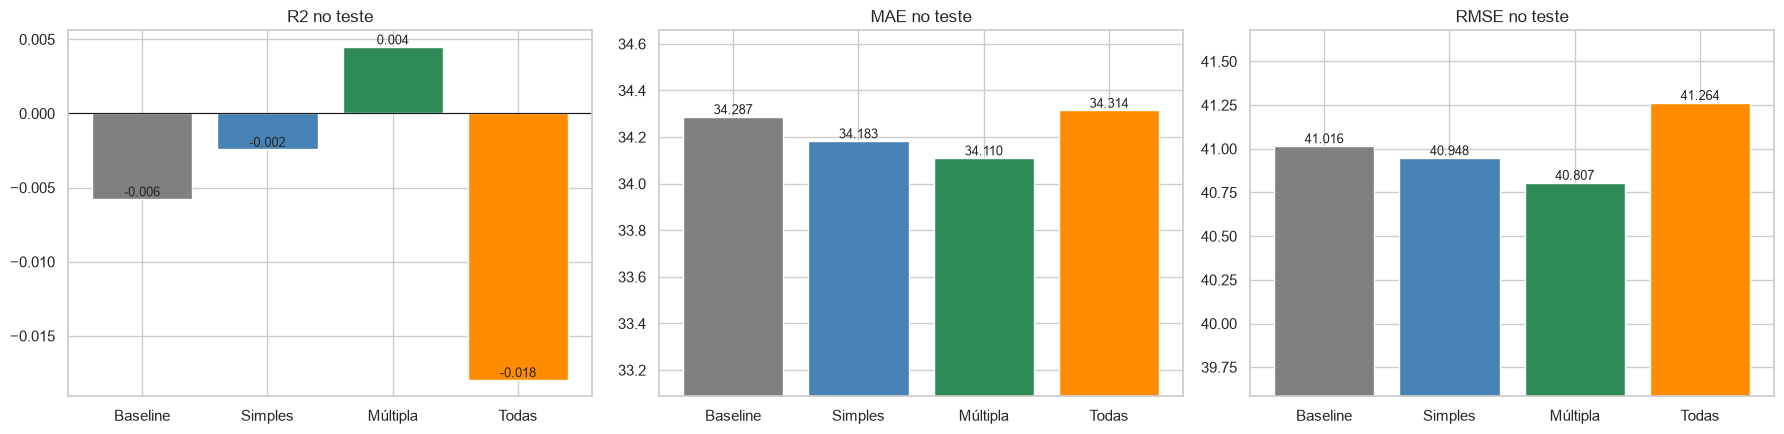

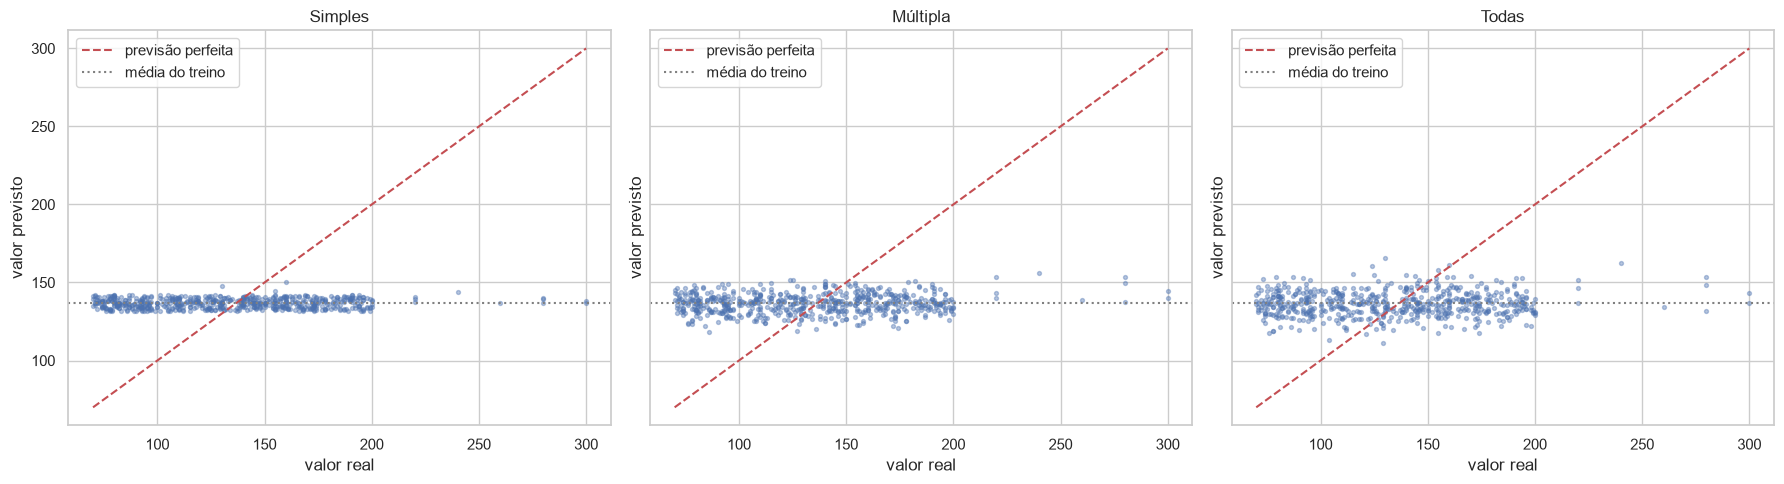

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
short = ['Baseline', 'Simples', 'Múltipla', 'Todas']
for ax, m in zip(axes, ['R2', 'MAE', 'RMSE']):
    vals = results[f'teste_{m}'].to_numpy()
    ax.bar(short, vals, color=['grey', 'steelblue', 'seagreen', 'darkorange'])
    ax.set_title(f'{m} no teste'); ax.axhline(0, color='k', lw=.8)
    for i, v in enumerate(vals): ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    if m != 'R2': ax.set_ylim(vals.min() * 0.97, vals.max() * 1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name, s in zip(axes, names[1:], short[1:]):
    ax.scatter(y_test, preds[name], s=8, alpha=.4)
    lims = [y_test.min(), y_test.max()]; ax.plot(lims, lims, 'r--', label='previsão perfeita')
    ax.axhline(y_train.mean(), color='grey', ls=':', label='média do treino')
    ax.set_xlabel('valor real'); ax.set_ylabel('valor previsto'); ax.set_title(s); ax.legend()
plt.tight_layout(); plt.show()

**Conclusões:**
- **Barras:** os quatro modelos têm métricas praticamente iguais (MAE entre 34.1 e 34.4; RMSE entre 40.8 e 41.3).
  As escalas dos gráficos de MAE e RMSE foram ampliadas para as diferenças serem visíveis; numa escala a partir de
  zero, as barras seriam indistinguíveis.
- **Previstos vs reais:** em vez de seguirem a diagonal vermelha, as previsões formam uma **faixa horizontal** à
  volta da média do treino (~137). Os pacientes com target 70 e os pacientes com target 300 recebem previsões
  semelhantes.

**Justificação:** é a imagem de um modelo que não encontrou nas features informação para distinguir pacientes. O
modelo múltiplo "abre" um pouco mais a faixa do que o simples, mas continua longe da diagonal.

### 4.4 Porque é que nenhuma feature explica o target? Um olhar final sobre `target_regression`

Antes da discussão, voltamos ao próprio target para perceber **de onde vem** a sua variação. Os gráficos de
valores reais vs previstos (2.5) sugerem que quase todos os valores estão espalhados de forma regular entre 70 e
200, com poucos valores acima. Verificamos:
- se, entre 70 e 200, a distribuição é compatível com uma **uniforme** (teste de Kolmogorov-Smirnov);
- quantos valores ficam acima de 200 e em que classe diagnóstica estão (uso apenas descritivo de `target_class`,
  como na EDA; não entra em nenhum modelo).

Valores entre 70 e 200: 1957 (97.9%) | KS vs uniforme(70, 200): D = 0.038, p = 0.00706
Valores acima de 200: 43 | por classe: {'DI_HY': 22, 'DI_HT': 21}
Proporcao de cada classe com target > 200: {'DI_HT': 0.247, 'DI_HY': 0.012, 'HT': 0.0}


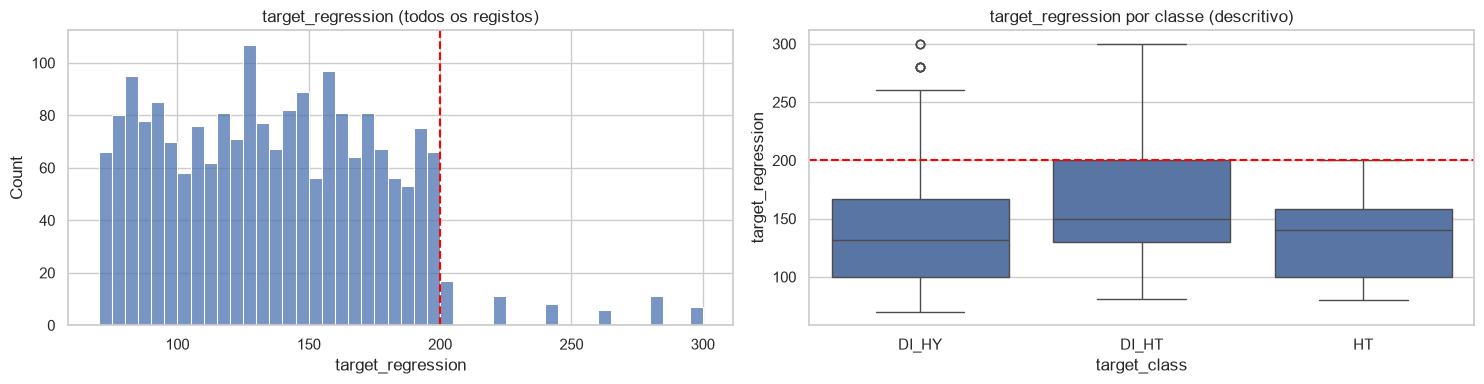

In [23]:
t = raw[TARGET]
inside = t[t <= 200]
ks_u = stats.kstest(inside, stats.uniform(loc=70, scale=130).cdf)
print(f'Valores entre 70 e 200: {len(inside)} ({len(inside)/len(t):.1%}) | KS vs uniforme(70, 200): '
      f'D = {ks_u.statistic:.3f}, p = {ks_u.pvalue:.3g}')
high = raw[t > 200]
print(f'Valores acima de 200: {len(high)} | por classe: {high.target_class.value_counts().to_dict()}')
print(f'Proporcao de cada classe com target > 200: '
      f'{(high.target_class.value_counts() / raw.target_class.value_counts()).fillna(0).round(3).to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(t, bins=46, ax=axes[0]); axes[0].axvline(200, color='red', ls='--')
axes[0].set_title('target_regression (todos os registos)')
sns.boxplot(data=raw, x='target_class', y=TARGET, ax=axes[1]); axes[1].axhline(200, color='red', ls='--')
axes[1].set_title('target_regression por classe (descritivo)')
plt.tight_layout(); plt.show()

**Conclusões:**
- **97.9%** dos valores do target estão entre 70 e 200, com uma distribuição **quase uniforme** (histograma plano).
  O teste KS rejeita a uniformidade perfeita (p = 0.007), mas a distância é pequena (D = 0.038). Com quase 2000
  valores, até desvios mínimos ficam "significativos".
- Apenas **43 valores (2.1%) passam os 200**, e concentram-se na classe `DI_HT`: **24.7% dos pacientes `DI_HT`**
  têm target > 200, contra 1.2% de `DI_HY` e 0% de `HT`.

**Justificação — o que isto explica:**
1. **Um target uniforme, sem relação com as features, é o pior cenário para uma regressão.** Num intervalo de 70 a
   200, todos os valores são igualmente prováveis para qualquer paciente, seja qual for o seu BMI, idade ou
   colesterol. Não há nada que o modelo possa aprender.
2. **A pouca estrutura que existe está ligada à classe diagnóstica** (valores altos em `DI_HT`), que não podemos
   usar como preditor. Isto explica também porque a EDA encontrou em `target_class` a variável mais associada ao
   target (η² ≈ 0.027).
3. Distribuições "planas" já tinham sido observadas em muitas features na EDA (secção 2.2). Reforça a hipótese de
   dados **sintéticos**, em que o target terá sido gerado de forma praticamente independente das features.

## 5. Comparação, discussão e conclusões

### 5.1 Comparação dos dois modelos

| | **Regressão Linear Simples** | **Regressão Linear Múltipla** |
|---|---|---|
| Features | `bmi` | `bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level` |
| Como foram escolhidas | Melhor de 30 features, testadas uma a uma | Construção incremental, confirmada por 286 combinações e 9 grupos clínicos |
| R² treino | 0.0055 | 0.0233 |
| R² teste | −0.002 | **0.005** |
| MAE teste | 34.18 | **34.11** |
| RMSE teste | 40.95 | **40.81** |
| Diferença de RMSE face à baseline (IC95%) | −0.07 [−0.29, +0.15] | −0.19 [−0.74, +0.32] |
| Significância | *t*: p = 0.006 | *F*: p = 2.8×10⁻⁵ |

**A regressão múltipla é ligeiramente melhor** nas três métricas, em validação cruzada e no teste. Ao juntar várias
features fracas e independentes, acumula pequenos contributos: o R² de treino é 4 vezes maior que o da simples.

**Mas nenhum dos dois modelos é útil na prática.** Ambos erram, em média, cerca de 34 unidades, praticamente o
mesmo que prever sempre a média (34.29). As diferenças não são estatisticamente robustas.

### 5.2 Discussão: o resultado faz sentido?

**Sim, e era previsível a partir da EDA.** A cadeia de raciocínio é a seguinte:

1. **A EDA mostrou que a melhor correlação com o target é r ≈ 0.07 (`bmi`).** Na regressão simples, R² = r², por isso
   o limite era 0.0055 (0.55%). O modelo atingiu exatamente esse valor (secções 2.1 e 2.2).
2. **As features são independentes entre si**, por isso, na regressão múltipla, os R² individuais somam-se
   aproximadamente. Somando os contributos das ~7 melhores features (todos abaixo de 0.6%) obtém-se ~2%, que foi o
   resultado obtido (3.8).
3. **As features que mais ajudam são as que têm maior |r| e estão acima do ruído** (`bmi`, `age`). As que pioram o
   modelo são as que, na EDA e no teste do ruído (2.3), não se distinguem de números aleatórios (`hdl`,
   `alcohol_intake`, `heart_rate`…).
4. **Mais features não é melhor.** Com 30 features o modelo memoriza ruído do treino (*overfitting*) e fica pior do
   que a média em dados novos (3.5 e 4.1).
5. **A forma do modelo não é o problema.** Os resíduos não mostram curvatura; polinómios e `log1p` não trazem
   ganhos robustos (2.7 e 3.7).
6. **O próprio target explica o resultado.** É quase uniforme entre 70 e 200 e só os valores raros acima de 200 têm
   alguma ligação, à classe `DI_HT` (4.4). Não há estrutura nas features para o modelo aprender.

**Paralelo com a classificação:** na EDA vimos que `target_class` é dominada por `DI_HY` (90%), e um classificador
sem boas features tenderá a prever quase sempre essa classe. Aqui acontece o equivalente na regressão: **sem
features informativas, o modelo de mínimos quadrados converge para a média** e prevê ~137 para quase todos os
pacientes (2.5, 4.3). Em ambos os casos, a comparação com a *baseline* (classe maioritária / média) é obrigatória
para não sobrestimar o modelo.

**Significância estatística ≠ capacidade de previsão.** Vários coeficientes têm p < 0.05 e o teste *F* do modelo
múltiplo é altamente significativo (p = 2.8×10⁻⁵). Com 1400 registos, até efeitos minúsculos se distinguem de
zero. O p-value diz que o efeito provavelmente **existe**; o R², o MAE e o RMSE dizem que é **demasiado pequeno**
para prever.

### 5.3 Conclusões
- **Regressão simples:** `target_regression = 125.06 + 0.425 × bmi`. O `bmi` é a melhor feature isolada em todos
  os critérios, mas explica apenas 0.55% da variância.
- **Regressão múltipla:** 7 features (`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`,
  `HbA1c_level`), que explicam cerca de 2% da variância. O trio `bmi` + `age` + `HbA1c_level` é uma alternativa
  quase equivalente e mais simples.
- **Desempenho no teste:** R² ≈ 0, MAE ≈ 34, RMSE ≈ 41. **Nenhum modelo prevê melhor do que a média** de forma
  estatisticamente robusta.
- **É um resultado negativo, mas válido:** foi obtido com uma metodologia correta (escolhas só no treino, validação
  cruzada, teste usado uma vez, *baseline*, controlo com ruído, intervalos de confiança) e é coerente com a EDA.